Import librairies


In [ ]:
from docling.datamodel.base_models import InputFormat
from docling.datamodel.pipeline_options import PdfPipelineOptions
from docling.document_converter import DocumentConverter, PdfFormatOption
from IPython.display import display
import json
import pandas as pd



In [ ]:
#Define PDF conversion
pipeline_options = PdfPipelineOptions()
pipeline_options.images_scale = 2
pipeline_options.generate_page_images =True

In [ ]:
#Intialize the converter with these options
document_conveter = DocumentConverter(
    format_options = {InputFormat.PDF : PdfFormatOption(pipeline_options=pipeline_options)}
)

In [ ]:
#Run the conversation
source = "/home/houssem_mabrouk/projects/prompt_chaining_task_routing/DoclingTechnicalReport.pdf"
result = document_conveter.convert(source)
doc = result.document

/home/houssem_mabrouk/projects/prompt_chaining_task_routing/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 770/770 [00:00<00:00, 2350.40it/s]
/home/houssem_mabrouk/projects/prompt_chaining_task_routing/.venv/lib/python3.14/site-packages/torch/nn/modules/conv.py:560: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/Convolution.cpp:1135.)
  return F.conv2d(
RapidOCR returned empty result!


In [20]:
print('The number of pages are : ', len(doc.pages))
print('The number of tables are :', len(doc.tables))
print('The number of pictures are :' , len(doc.pictures))


The number of pages are :  9
The number of tables are : 3
The number of pictures are : 5


In [21]:
print(doc.export_to_markdown())

<!-- image -->

## Docling Technical Report

## Version 1.0

Christoph Auer Maksym Lysak Ahmed Nassar Michele Dolfi Nikolaos Livathinos Panos Vagenas Cesar Berrospi Ramis Matteo Omenetti Fabian Lindlbauer Kasper Dinkla Lokesh Mishra Yusik Kim Shubham Gupta Rafael Teixeira de Lima Valery Weber Lucas Morin Ingmar Meijer Viktor Kuropiatnyk Peter W. J. Staar

AI4K Group, IBM Research R¨uschlikon, Switzerland

## Abstract

This technical report introduces Docling, an easy to use, self-contained, MITlicensed open-source package for PDF document conversion. It is powered by state-of-the-art specialized AI models for layout analysis (DocLayNet) and table structure recognition (TableFormer), and runs efficiently on commodity hardware in a small resource budget. The code interface allows for easy extensibility and addition of new features and models.

## 1 Introduction

Converting PDF documents back into a machine-processable format has been a major challenge for decades due to their huge variab

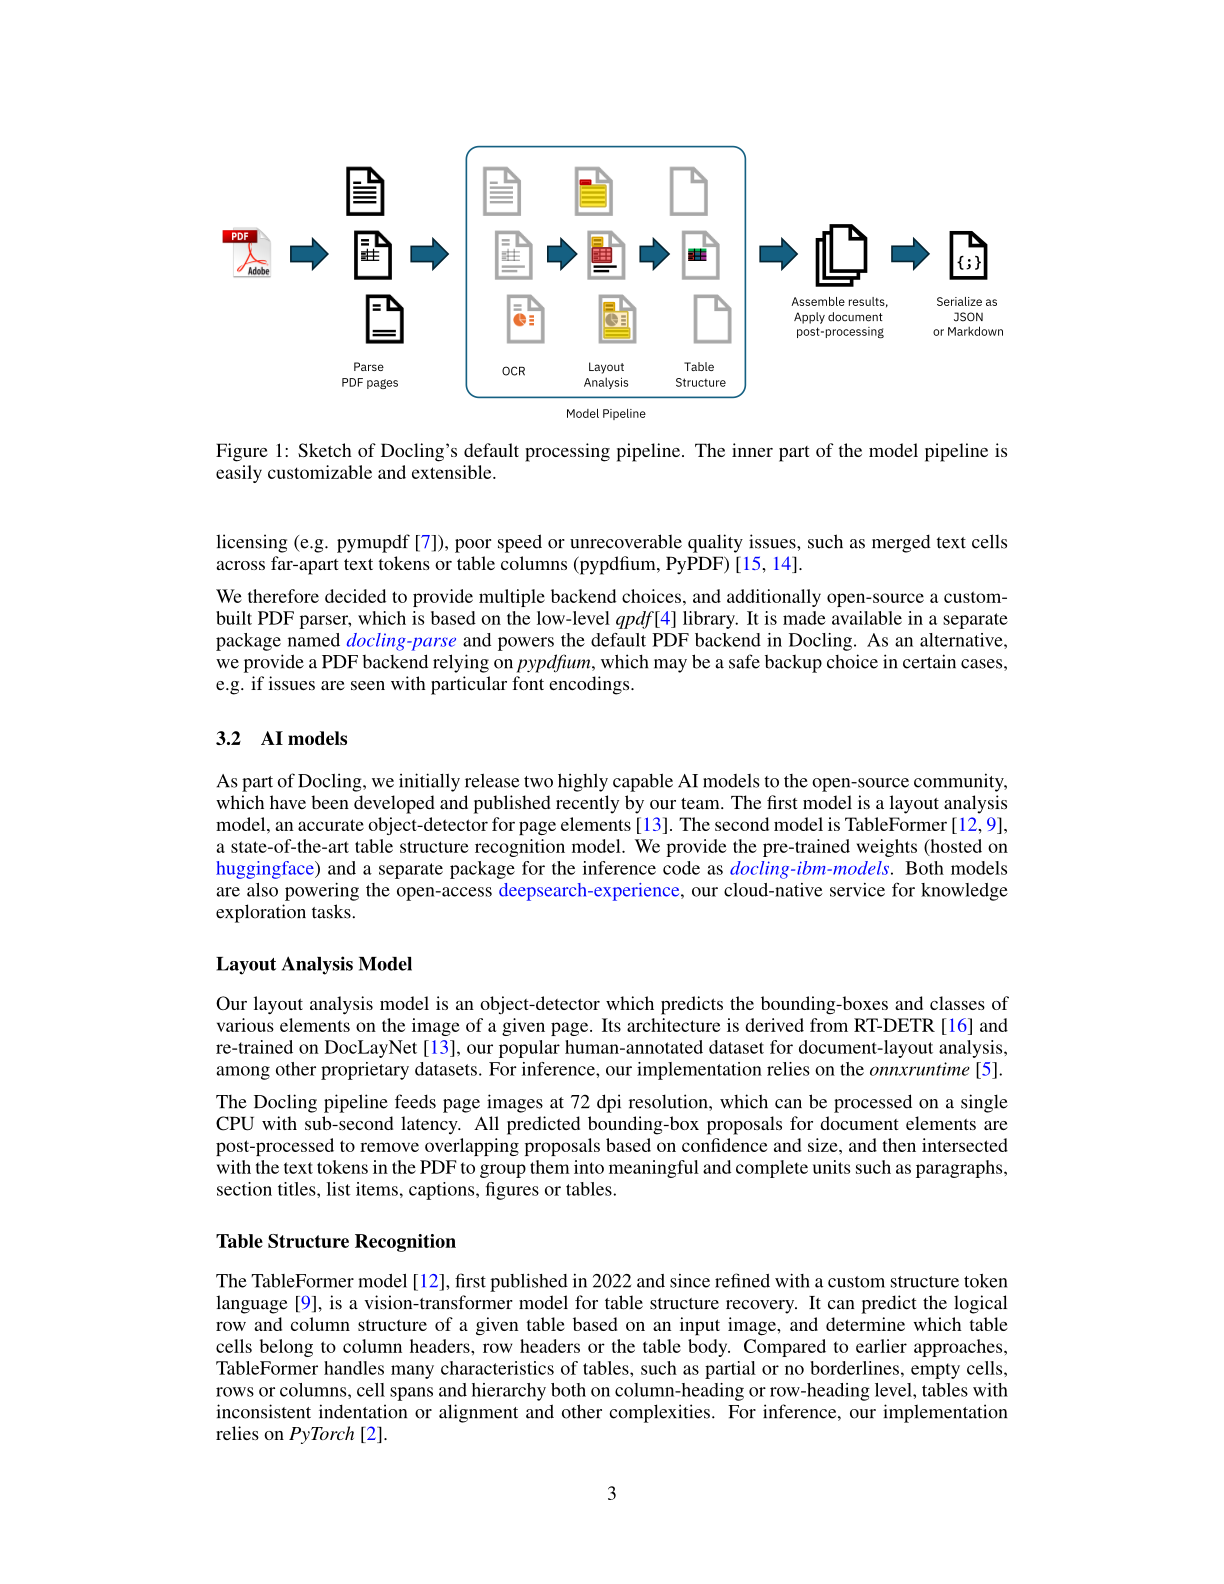

In [22]:
#printing the third page
display(doc.pages[3].image.pil_image)

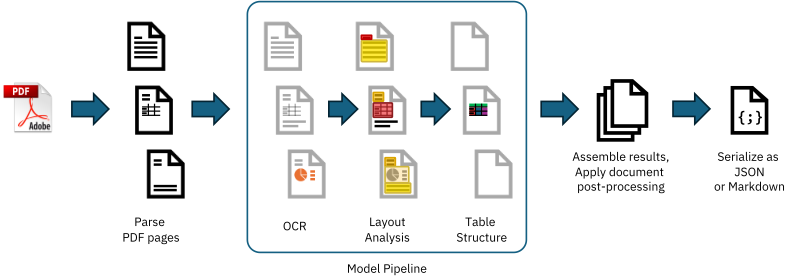

In [26]:
#displaying embedded images
image = doc.pictures[1].get_image(doc=doc)
display(image)

In [27]:
#displaying embedded tables as pandas dataframes
table_df = doc.tables[0].export_to_dataframe(doc=doc)
table_df

,CPU.,Thread budget.,native backend.TTS,native backend.Pages/s,native backend.Mem,pypdfium backend.TTS,pypdfium backend.Pages/s,pypdfium backend.Mem
0,Apple M3 Max,4 16,177 s 167 s,1.27 1.34,6.20 GB,103 s 92 s,2.18 2.45,2.56 GB
1,(16 cores) Intel(R) Xeon E5-2690 (16 cores),4 16,375 s 244 s,0.60 0.92,6.16 GB,239 s 143 s,0.94 1.57,2.42 GB


In [28]:
#exporting the docling object to a dictionary representation
doc_dict = doc.export_to_dict()
#saving the dict version of the document to disk for later reloading
with open("document_serialized.json","w",encoding="utf-8") as f:
    json.dump(doc_dict,f,ensure_ascii=False, indent=2)

In [30]:
#processing the jpg image
source = "/home/houssem_mabrouk/projects/prompt_chaining_task_routing/image_invoice.jpg"
result = document_conveter.convert(source)
doc = result.document

#confirming the jpg image object
print(doc.export_to_markdown())

## Invoice no: 51109338

Date of issue:

04/13/2013

## Seller:

## Client:

Andrews, Kirby and Valdez 58861 Gonzalez Prairie Lake Daniellefurt, IN 57228

Becker Ltd 8012Stewart Summit Apt. 455 North Douglas, AZ 95355

Tax Id: 945-82-2137

IBAN:GB75MCRL06841367619257

## ITEMS

|   No. | Description                                                                     | Qty   | UM   | Net price   | Net worth   | VAT [%]   | Gross worth   |
|-------|---------------------------------------------------------------------------------|-------|------|-------------|-------------|-----------|---------------|
|    1. | CLEARANCE! Fast Dell Desktop Computer PC DUAL CORE WINDOWS 10 4/8/16GB RAM      | 3,00  | each | 209,00      | 627,00      | 10%       | 689,70        |
|    2. | HP T520 Thin Client Computer AMD GX-212JC 1.2GHz 4GB RAM TESTED!!READ BELOW!!   | 5,00  | each | 37,75       | 188,75      | 10%       | 207,63        |
|    3. | gaming pc desktop computer                                 

In [32]:
#processing the word document
source = "/home/houssem_mabrouk/projects/prompt_chaining_task_routing/word_invoice.docx"
result = document_conveter.convert(source)
doc = result.document

#confirming the word document object
print(doc.export_to_markdown())

<!-- image -->

INVOICE

**Invoice to:                                                                   Invoice#                            52131**

**Daniel Gallego                                                                          Date   01 / 02 / 2023**

123 Rent  St.,

New York, ST 12345

| **Item**   |   **Quantity** | **Unit Price**   | Total     |
|------------|----------------|------------------|-----------|
| House      |              1 | 800$             | 800$      |
| Rent       |              1 | 500$             | 500$      |
| Service    |              1 | 90$              | 90$       |
|            |                | **Subtotal**     | **1567$** |
|            |                | **Tax (0%)**     | $0        |
|            |                | **Total**        | **1980$** |

**Thank you for your business!     \_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_\_**

<!-- image -->


In [10]:
import sys
print(sys.executable)

/home/houssem_mabrouk/projects/prompt_chaining_task_routing/.venv/bin/python


In [11]:
%pip install docling


Note: you may need to restart the kernel to use updated packages.
